# eunoia 0.6.0 — testing & contribution notebook

Works through the VISET × eunoia checklist (A → G) on the public drug-target sample files.
Record findings with `log(...)`; the summary table at the end is what goes to Johan.

- **Glyphs = dots (how many).** `plot(glyphs=True)`
- **Itemisation = names (who).** `plot(members={"mode": "packed"})`

Run in the `viset` conda env. No unpublished lab data in this notebook.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import eunoia as eu

print("eunoia", eu.__version__)

DATA = Path("../../Drug target sample files")

def genes(f):
    return pd.read_csv(DATA / f)["Gene names"].dropna().tolist()

# every drug file, keyed by drug name ("5. ATORVASTATIN_sample.csv" -> "Atorvastatin")
D = {re.sub(r"^\d+\. |_sample$", "", f.stem).title(): genes(f.name) for f in DATA.glob("*.csv")}

# drug classes = union of their drugs' genes (bigger real sets for crowding tests)
CLASSES = {
    "Statins": ["Atorvastatin", "Simvastatin", "Lovastatin", "Pravastatin"],
    "Kinase inhibitors": ["Imatinib", "Gefitinib", "Erlotinib", "Sunitinib"],
    "NSAIDs": ["Ibuprofen", "Celecoxib", "Diclofenac", "Indomethacin"],
    "Antipsychotics": ["Haloperidol", "Olanzapine"],
}
for c, drugs in CLASSES.items():
    D[c] = sorted(set().union(*(D[d] for d in drugs)))

A, S, U = D["Atorvastatin"], D["Simvastatin"], D["Sunitinib"]
print(len(A), len(S), len(U))

eunoia 0.6.0
51 46 39


In [2]:
FINDINGS = []

def log(section, note, owner="?"):
    """owner: 'johan-rust', 'mine-python', 'docs', or '?'"""
    FINDINGS.append({"section": section, "owner": owner, "note": note})

# show every "did not fit" warning, not just the first one per cell
warnings.simplefilter("always", UserWarning)

## A. Itemisation (packed members)
Per trial: region correct? names in right region? overlap / clip / drop? font size?

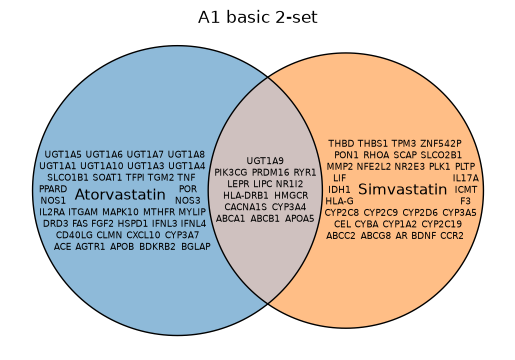

EulerFit (2 circles, diag_error=1.277e-14, stress=5.76e-28, loss=6.134e-28)
                              original      fitted    residual regionError
  Atorvastatin&Simvastatin          14          14  -1.259e-12   1.277e-14
  Atorvastatin                      37          37   1.421e-14    6.55e-15
  Simvastatin                       32          32   4.263e-14   6.106e-15

In [3]:
# basic 2-set
fit2 = eu.euler({"Atorvastatin": A, "Simvastatin": S})
fit2.plot(members={"mode": "packed"})
plt.title("A1 basic 2-set")
plt.show()
fit2

c:\Users\user\anaconda3\envs\viset\Lib\site-packages\eunoia\_models.py:284: UserWarning: packed member labels did not fit: {'Atorvastatin&Sunitinib': 1, 'Atorvastatin&Simvastatin': 1}
  return render(


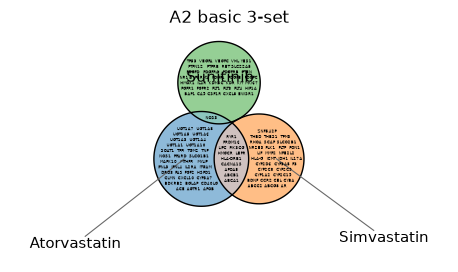

EulerFit (3 circles, diag_error=0.01695, stress=0.001103, loss=0.001103)
                                        original      fitted    residual regionError
  Atorvastatin&Simvastatin                    12          12   2.801e-11    0.001753
  Atorvastatin                                35          35  -2.959e-11    0.005114
  Atorvastatin&Sunitinib                       2           2   1.578e-12   0.0002922
  Atorvastatin&Simvastatin&Sunitinib           2           0           2     0.01695
  Simvastatin                                 32          32   1.845e-08    0.004676
  Sunitinib                                   35          35   1.848e-08    0.005114

In [7]:
# basic 3-set
fit3 = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=5)
fig, ax = plt.subplots(figsize=(15, 3))
fit3.plot(ax=ax, members={"mode": "packed"})
ax.set_title("A2 basic 3-set")
#plt.savefig("images/A2 set of 3_Fig size 15 and 3_other version.png")
plt.show()
fit3

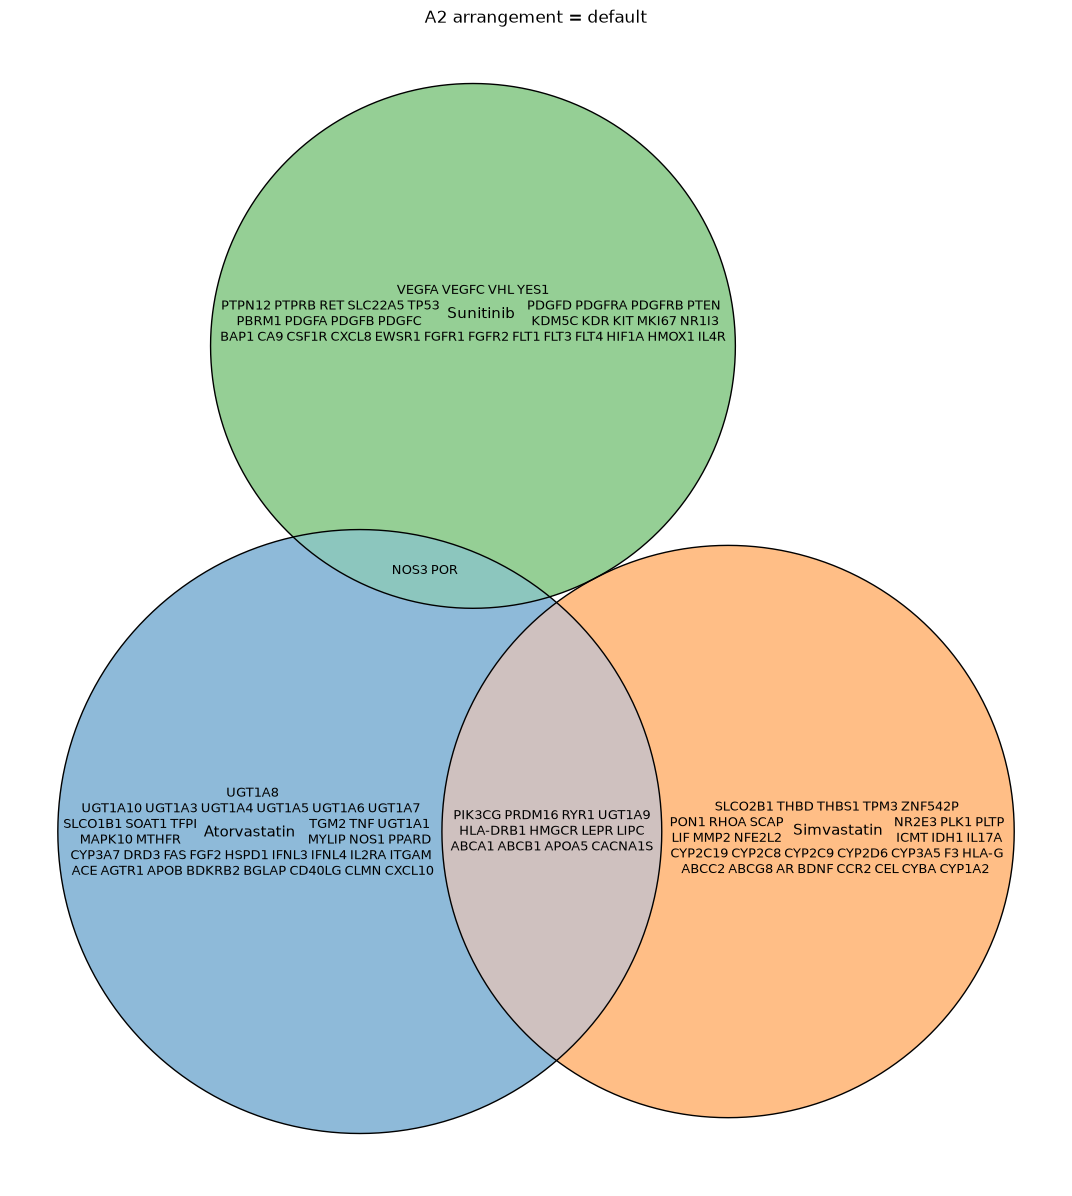

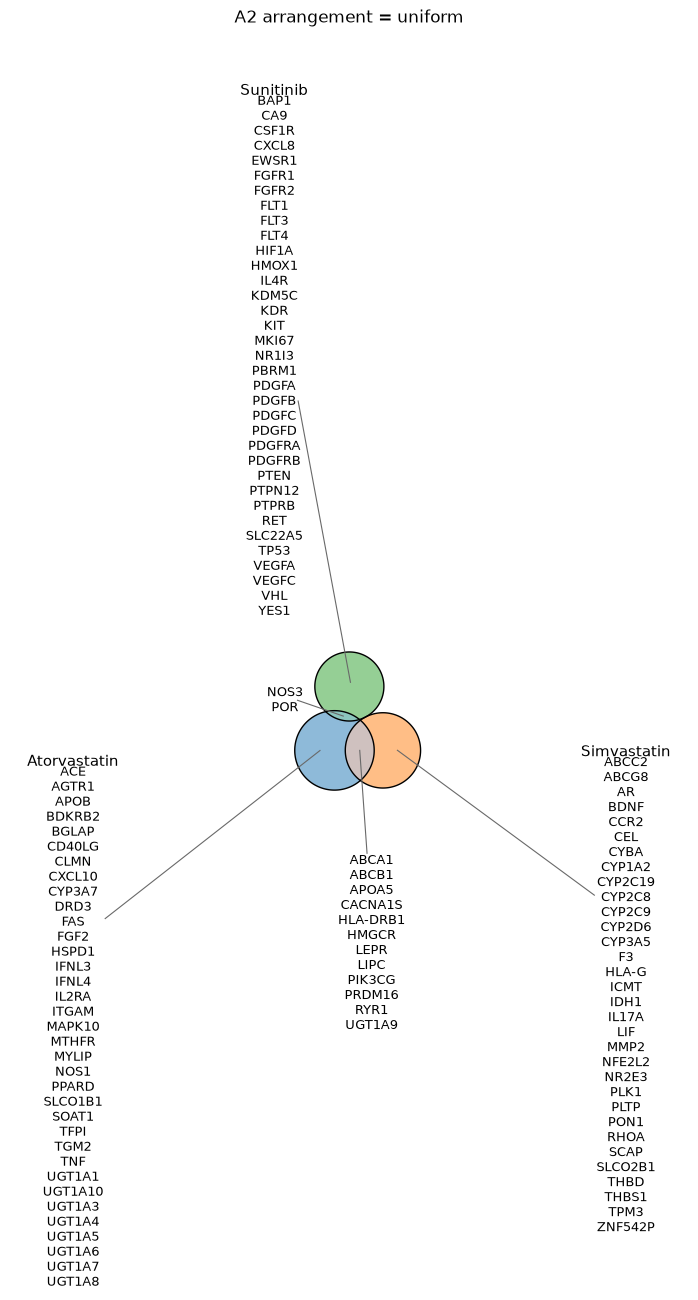

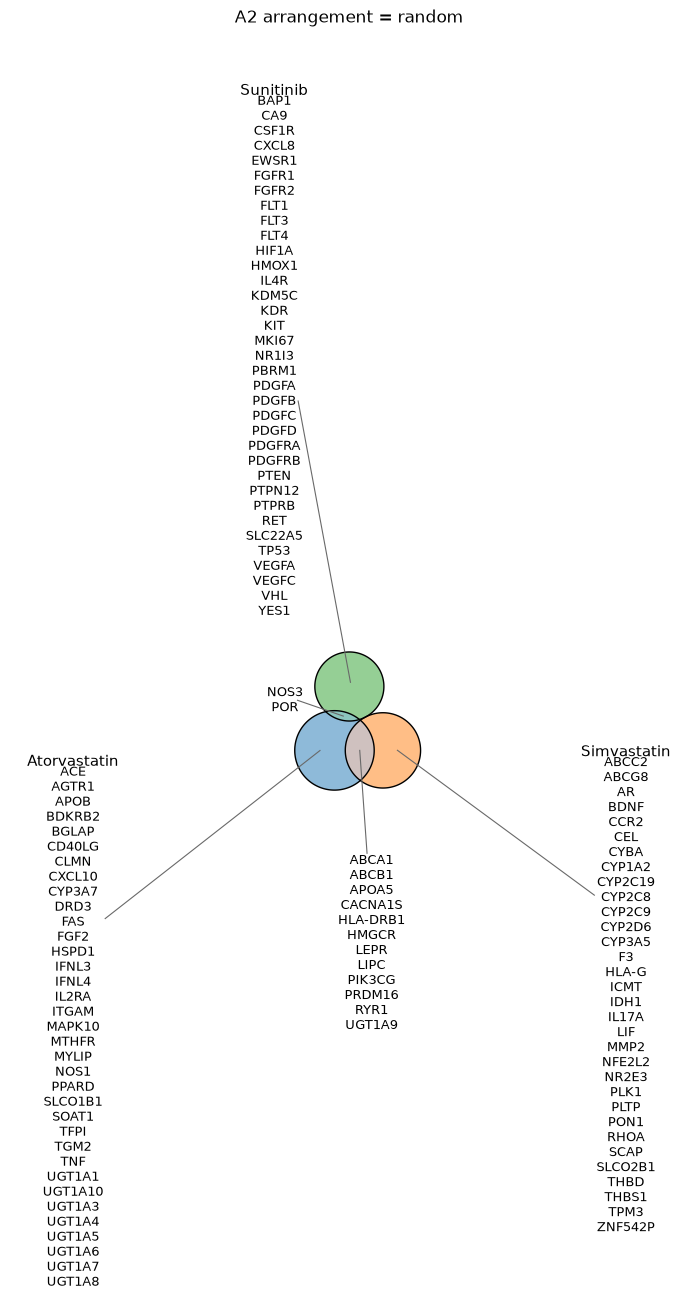

In [6]:
# A2b. arrangement at figsize 15x15: default vs "uniform" vs "random" (only 2 options exist)
for arr in [None, "uniform", "random"]:
    members = {"mode": "packed"} if arr is None else {"mode": "list", "arrangement": arr}
    fig, ax = plt.subplots(figsize=(15, 15))
    fit3.plot(ax=ax, members=members)
    ax.set_title(f"A2 arrangement = {arr or 'default'}")
    #plt.savefig(f"images/A2 arrangement_{arr or 'default'}_15x15.png", dpi=200, bbox_inches="tight")
    plt.show()

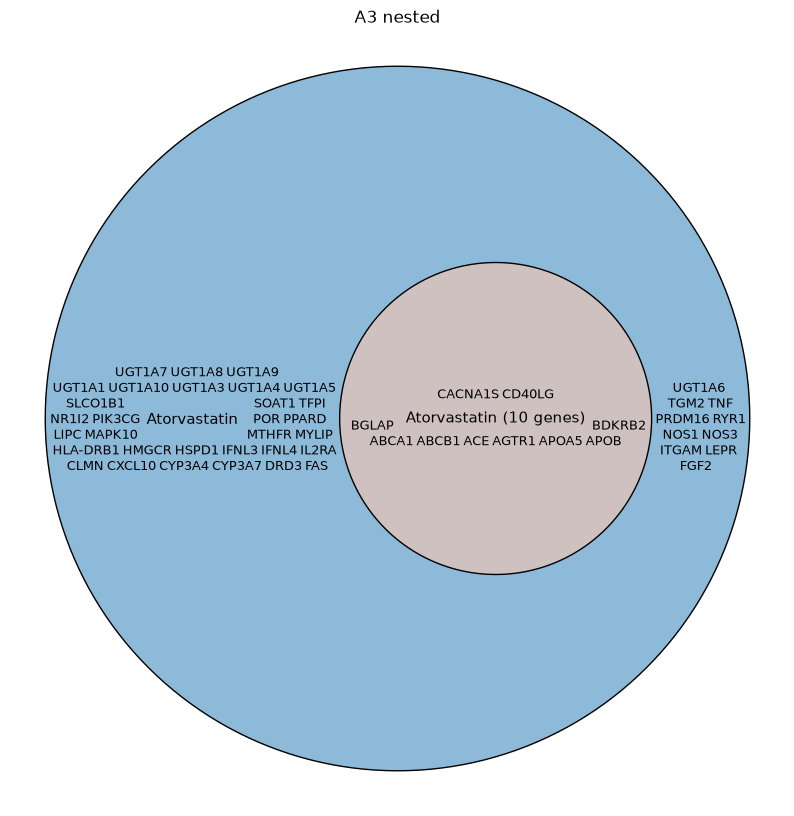

In [40]:
# nested set
fig, ax = plt.subplots(figsize=(10, 15))
eu.euler({"Atorvastatin": A, "Atorvastatin (10 genes)": A[:10]}).plot(ax=ax,members={"mode": "packed"})
plt.title("A3 nested")
#plt.savefig("images/A3 nested.png", dpi=200, bbox_inches="tight")
plt.show()

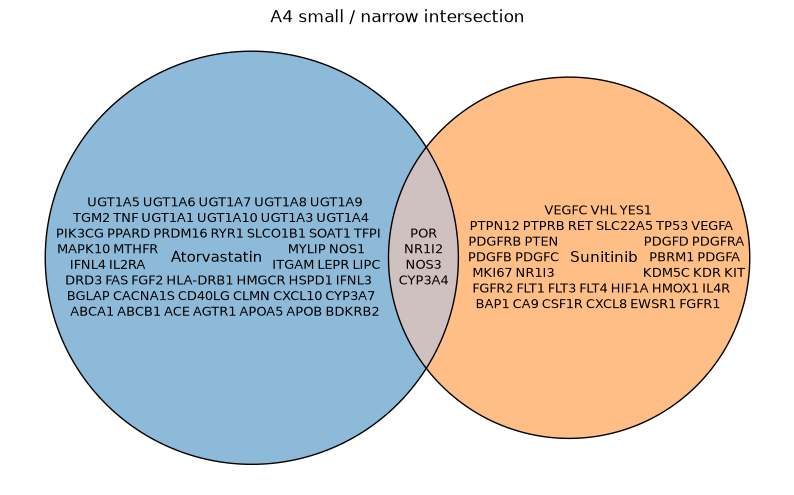

In [4]:
# small / narrow intersection (only 4 shared genes)
fig, ax = plt.subplots(figsize=(10, 15))
eu.euler({"Atorvastatin": A, "Sunitinib": U}).plot(ax=ax,members={"mode": "packed"})
plt.title("A4 small / narrow intersection")
plt.show()

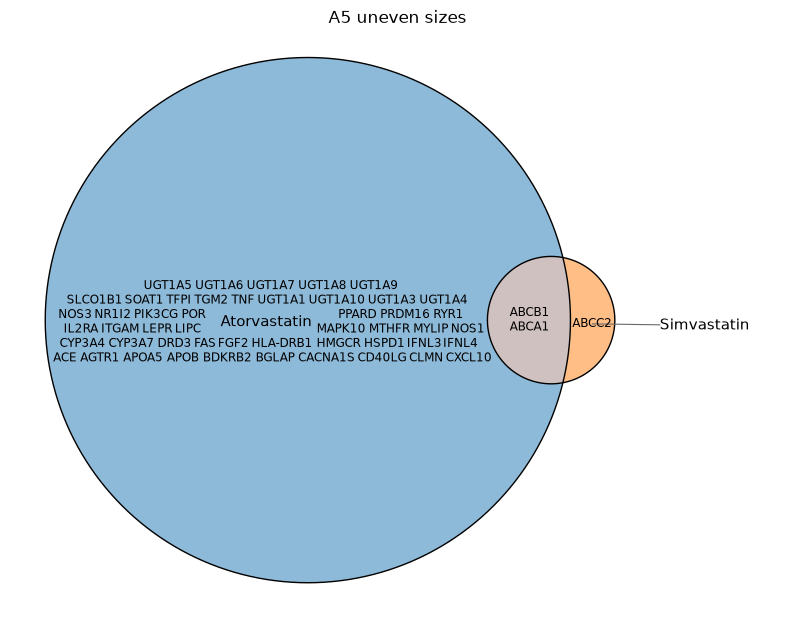

In [ ]:
# uneven sizes: 51 genes vs 3 (Simvastatin's first 3 genes)
fig, ax = plt.subplots(figsize=(10, 8))
eu.euler({"Atorvastatin": A, "Simvastatin": S[:3]}).plot(ax=ax, members={"mode": "packed"})
ax.set_title("A5 uneven sizes")
plt.savefig("images/A5 Uneven sizes.png", dpi=200, bbox_inches="tight")
plt.show()

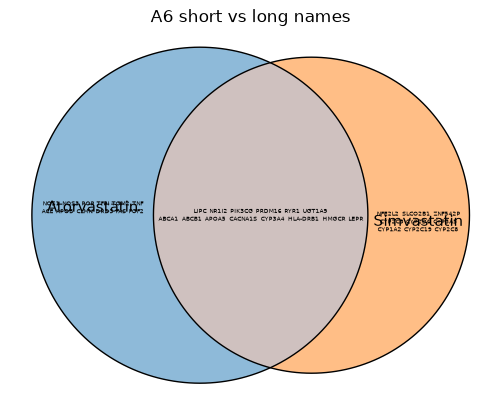

In [8]:
# short vs long names: Atorvastatin-only genes <= 4 chars, Simvastatin-only genes >= 6 chars,
# overlap keeps all 14 shared genes (mixed lengths)
shared = set(A) & set(S)
eu.euler({"Atorvastatin": [g for g in A if len(g) <= 4 or g in shared],
          "Simvastatin": [g for g in S if len(g) >= 6 or g in shared]}).plot(members={"mode": "packed"})
plt.title("A6 short vs long names")
#plt.savefig("images/A6_short_vs_long_names.png", dpi=200, bbox_inches="tight")
plt.show()

### A7. Overflow — are names silently dropped?

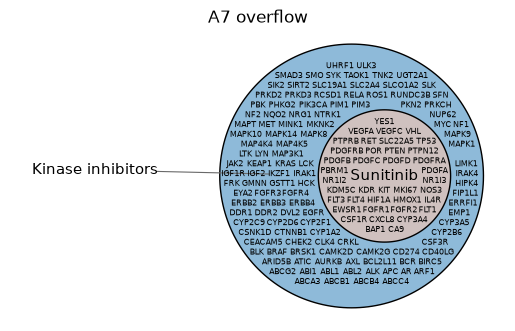

0 warning(s) — names dropped: False


In [9]:
# overflow: 155 kinase-inhibitor genes with Sunitinib's 39 nested inside
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    eu.euler({"Kinase inhibitors": D["Kinase inhibitors"], "Sunitinib": U}).plot(members={"mode": "packed"})
plt.title("A7 overflow")
plt.show()
for x in w:
    print("WARNING:", x.message)
print(f"{len(w)} warning(s) — names dropped: {bool(w)}")

### O. Overflow: which names go missing? Default font vs IBM Plex Mono vs Inter

In [3]:
# register the fonts in VISET/Font so matplotlib can use them by name
from matplotlib import font_manager

FONTS = Path("../../Font")
font_manager.fontManager.addfont(str(FONTS / "IBM_Plex_Mono" / "IBMPlexMono-Regular.ttf"))
font_manager.fontManager.addfont(str(FONTS / "Inter" / "Inter-Regular.ttf"))
# default font is "DejaVu Sans"; now "IBM Plex Mono" and "Inter" work too

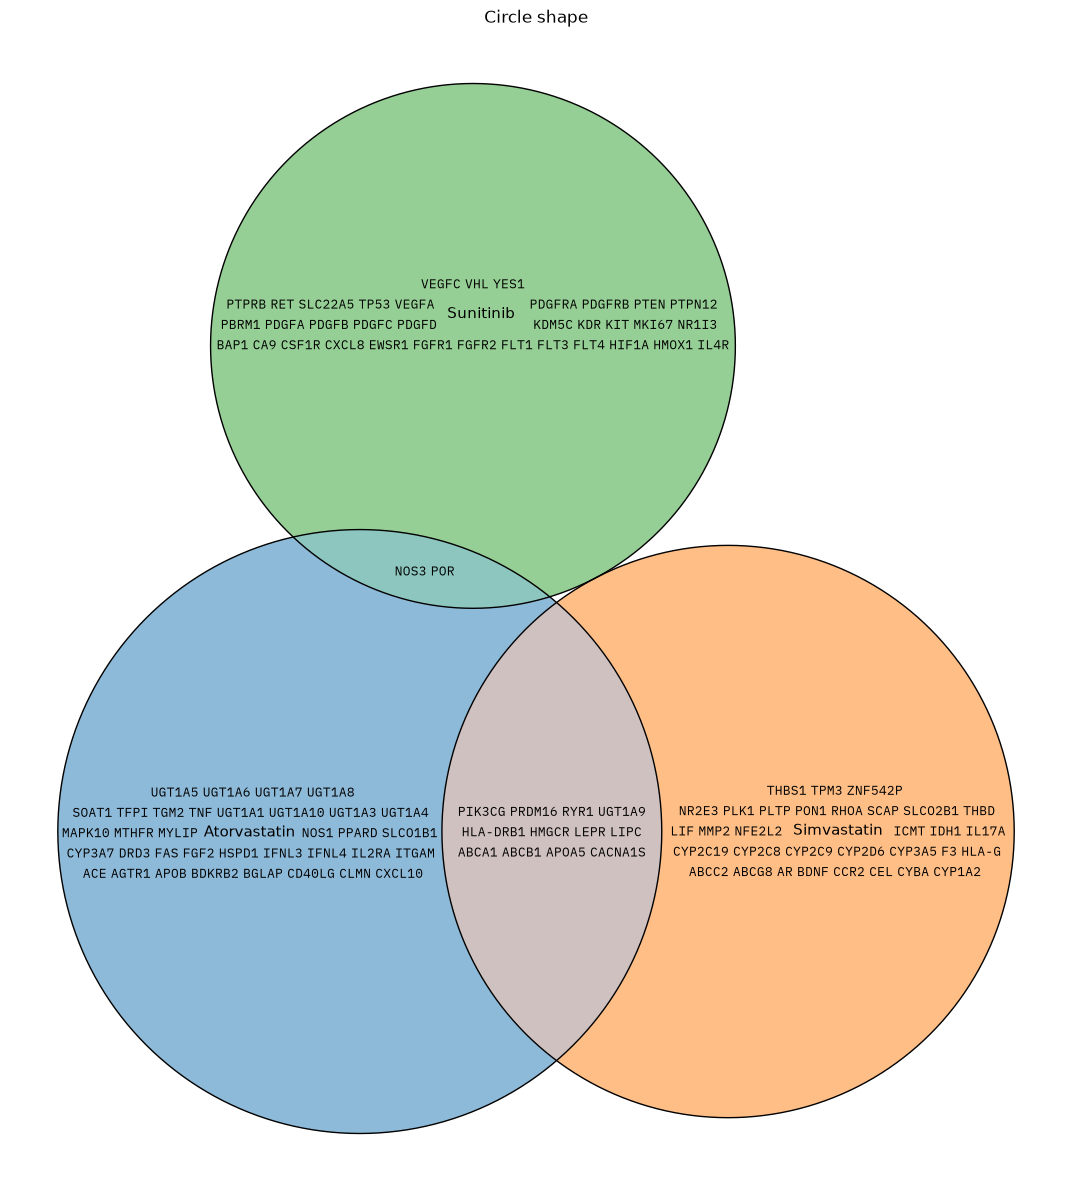

Atorvastatin&Simvastatin&Sunitinib not drawn: ['CYP3A4', 'NR1I2']
fonts drawn: {'DejaVu Sans', 'IBM Plex Mono'}


In [8]:
fit = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, shape = "circle", seed=1)
fig, ax = plt.subplots(figsize=(15,15))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")   # fresh warnings every run, not once per session
    fit.plot(ax=ax, members={"mode": "packed", "fontfamily": "IBM Plex Mono"})
ax.set_title("Circle shape")
#plt.savefig("images/Square shape_listmode.png")
plt.show()

# which names are missing, from eunoia's own "did not fit" count
# (eunoia stops at the first name that doesn't fit, so the missing ones are the last N in each region's list)
import ast
dropped = {}
for w in caught:
    msg = str(w.message)
    print("WARNING:", msg)
    if "did not fit" in msg:
        dropped = ast.literal_eval(msg.split(": ", 1)[1])
for region, n in dropped.items():
    print(region, "missing:", fit.members[region][-n:])

# regions with members that eunoia didn't draw at all (zero area, never in the warning)
for region, names in fit.members.items():
    if names and fit.fitted_values.get(region, 0) == 0:
        print(region, "not drawn:", names)

print("fonts drawn:", {t.get_fontname() for t in ax.texts})

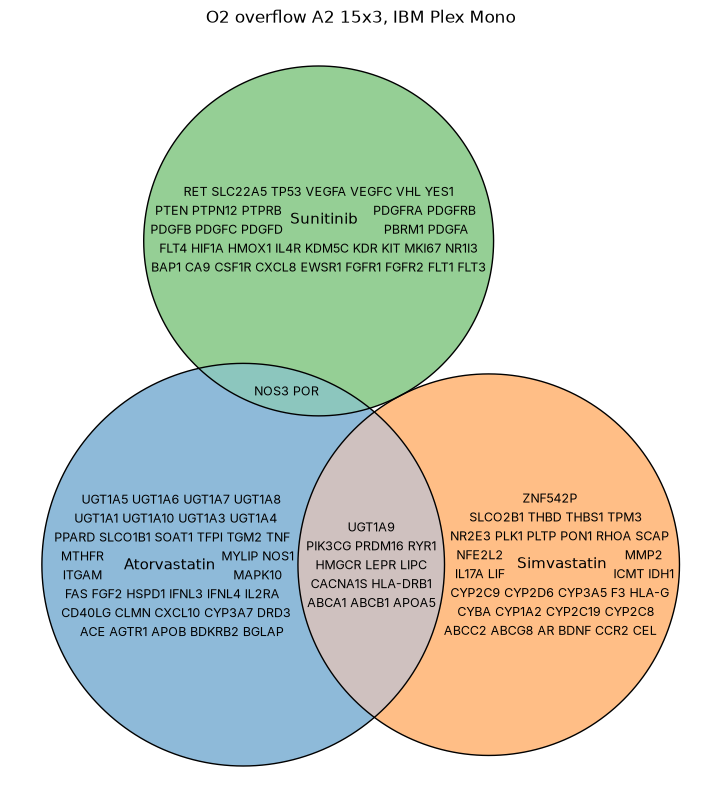

In [8]:
fit = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=1)
fig, ax = plt.subplots(figsize=(10, 10))
fit.plot(ax=ax, members={"mode": "packed", "fontfamily": "Inter"})
ax.set_title("O2 overflow A2 15x3, IBM Plex Mono")
#plt.savefig("images/O2 overflow A2 15x3 IBM Plex Mono.png", dpi=200, bbox_inches="tight")
plt.show()

# which names are missing from the plot (set labels taken out first)
# drawn = [t.get_text() for t in ax.texts]
# for name in ["Atorvastatin", "Simvastatin", "Sunitinib"]:
#     if name in drawn:
#         drawn.remove(name)
# for region, names in fit.members.items():
#     missing = [n for n in names if n not in drawn]
#     if missing:
#         print(region, "missing:", missing)

In [ ]:
fit = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=1)
fig, ax = plt.subplots(figsize=(15, 3))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")   # fresh warnings every run, not once per session
    fit.plot(ax=ax, members={"mode": "packed", "fontfamily": "Inter"})
ax.set_title("O3 overflow A2 15x3, Inter")
#plt.savefig("images/O3 overflow A2 15x3 Inter.png", dpi=200, bbox_inches="tight")
plt.show()

# which names are missing, from eunoia's own "did not fit" count
# (eunoia stops at the first name that doesn't fit, so the missing ones are the last N in each region's list)
import ast
dropped = {}
for w in caught:
    msg = str(w.message)
    print("WARNING:", msg)
    if "did not fit" in msg:
        dropped = ast.literal_eval(msg.split(": ", 1)[1])
for region, n in dropped.items():
    print(region, "missing:", fit.members[region][-n:])

# regions with members that eunoia didn't draw at all (zero area, never in the warning)
for region, names in fit.members.items():
    if names and fit.fitted_values.get(region, 0) == 0:
        print(region, "not drawn:", names)

print("fonts drawn:", {t.get_fontname() for t in ax.texts})

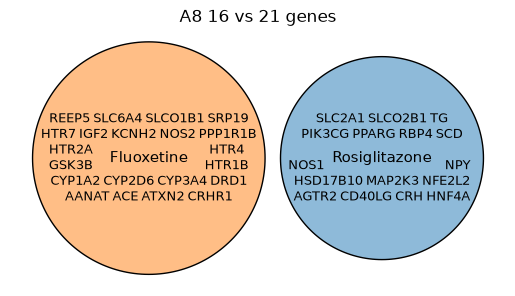

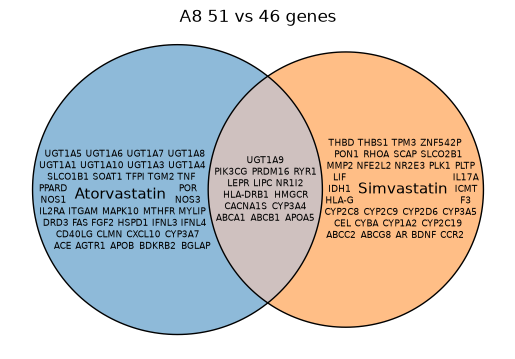

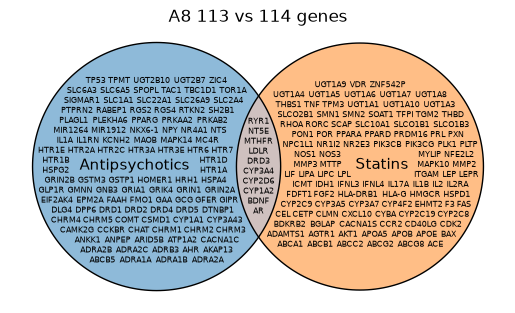

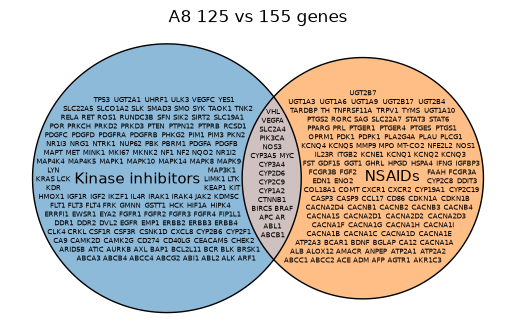

In [10]:
# scale up member counts (~20 -> ~50 -> ~115 -> ~150 per set): where does auto-sizing give up?
for a, b in [("Rosiglitazone", "Fluoxetine"), ("Atorvastatin", "Simvastatin"),
             ("Statins", "Antipsychotics"), ("NSAIDs", "Kinase inhibitors")]:
    eu.euler({a: D[a], b: D[b]}).plot(members={"mode": "packed"})
    plt.title(f"A8 {len(D[a])} vs {len(D[b])} genes")
    plt.show()

### A9. Knobs: font, arrangement, min_scale

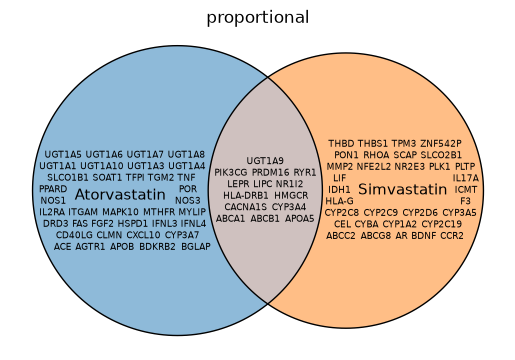

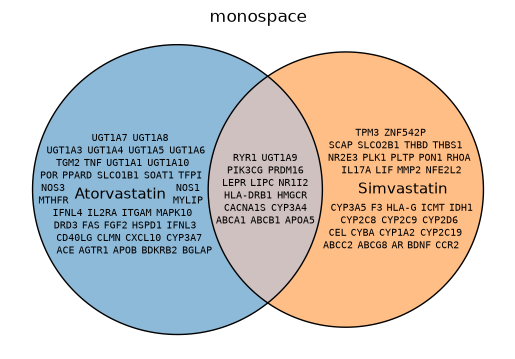

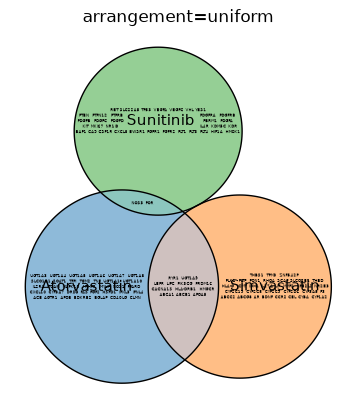

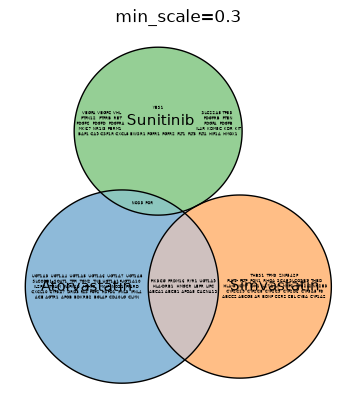

In [11]:
sets2 = {"Atorvastatin": A, "Simvastatin": S}
sets3 = {"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}

# proportional font (default)
eu.euler(sets2).plot(members={"mode": "packed"})
plt.title("proportional")
plt.show()

# monospace font
eu.euler(sets2).plot(members={"mode": "packed", "fontfamily": "monospace"})
plt.title("monospace")
plt.show()

# uniform arrangement
eu.euler(sets3).plot(members={"mode": "packed", "arrangement": "uniform"})
plt.title("arrangement=uniform")
plt.show()

# allow names to shrink further
eu.euler(sets3).plot(members={"mode": "packed", "min_scale": 0.3})
plt.title("min_scale=0.3")
plt.show()

In [12]:
log("A", "TODO: itemisation observations")

## B. Glyphs (dots) — same diagrams, for comparison
Countable at low/med/high? Spacing, collisions, shrinking?

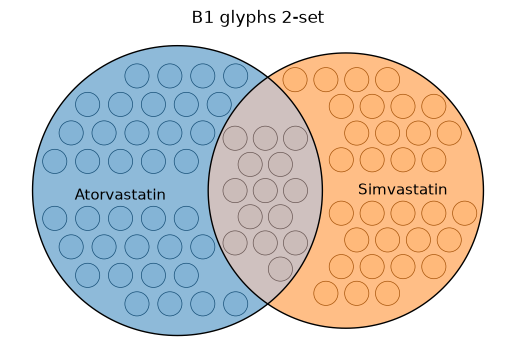

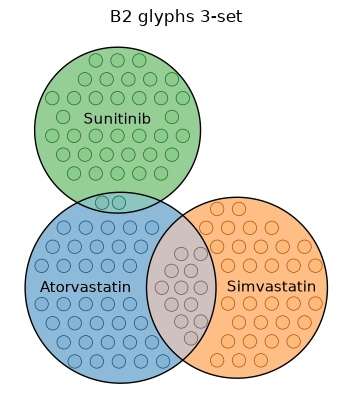

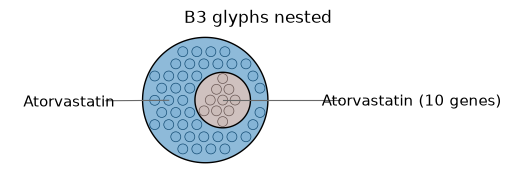

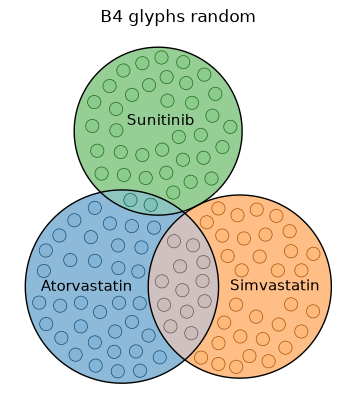

In [12]:
# glyphs 2-set
eu.euler(sets2).plot(glyphs=True)
plt.title("B1 glyphs 2-set")
plt.show()

# glyphs 3-set
eu.euler(sets3).plot(glyphs=True)
plt.title("B2 glyphs 3-set")
plt.show()

# glyphs nested set
eu.euler({"Atorvastatin": A, "Atorvastatin (10 genes)": A[:10]}).plot(glyphs=True)
plt.title("B3 glyphs nested")
plt.show()

# glyphs random arrangement
eu.euler(sets3).plot(glyphs={"arrangement": "random", "seed": 0})
plt.title("B4 glyphs random")
plt.show()

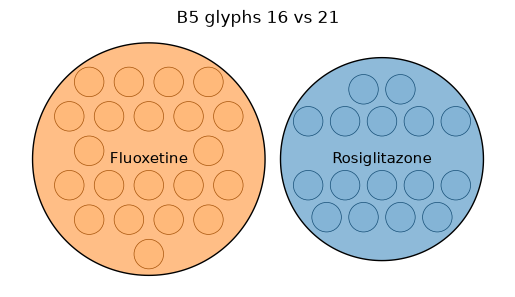

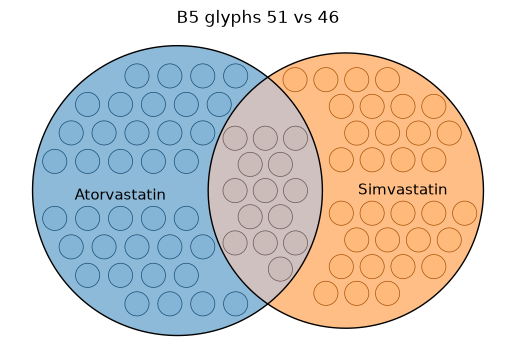

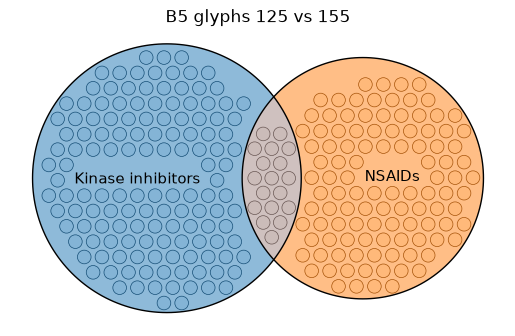

In [13]:
# dot counts low / medium / high (~20, ~50, ~150 per set)
for a, b in [("Rosiglitazone", "Fluoxetine"), ("Atorvastatin", "Simvastatin"), ("NSAIDs", "Kinase inhibitors")]:
    eu.euler({a: D[a], b: D[b]}).plot(glyphs=True)
    plt.title(f"B5 glyphs {len(D[a])} vs {len(D[b])}")
    plt.show()

In [15]:
log("B", "TODO: glyph layout suggestions (rows/grid vs scatter, overflow)")

## C. Label placement — hunt bad cases (for Johan, Rust)
Save code + screenshot + note for each bad one.

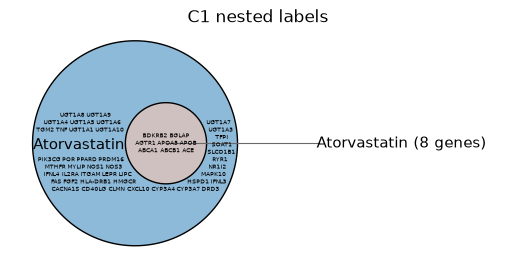

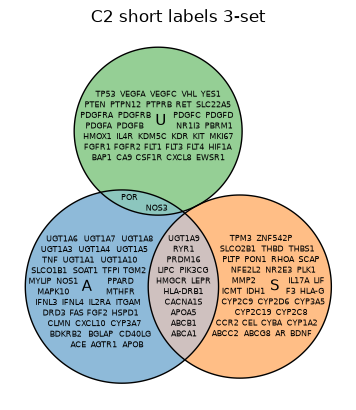

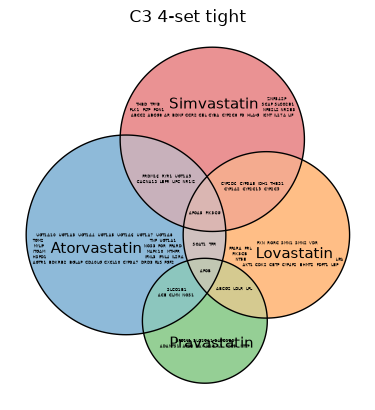

In [14]:
# nested set labels
eu.euler({"Atorvastatin": A, "Atorvastatin (8 genes)": A[:8]}).plot(members={"mode": "packed"})
plt.title("C1 nested labels")
plt.show()

# short set labels (drug initials)
eu.euler({"A": A, "S": S, "U": U}).plot(members={"mode": "packed"})
plt.title("C2 short labels 3-set")
plt.show()

# 4-set tight overlaps (all four statins)
eu.euler({d: D[d] for d in CLASSES["Statins"]}).plot(members={"mode": "packed"})
plt.title("C3 4-set tight")
plt.show()

In [17]:
log("C", "TODO: bad label cases", owner="johan-rust")

## D. Interactive (plotly)

In [3]:
fit3 = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=1)
fig = fit3.plot_plotly(width=900, height=None)
fig.update_layout(title="interactive, width 700")
fig.show()

In [19]:
fit3 = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=1)
fig = fit3.plot_plotly(width=700, height=None, glyphs=True)
fig.update_layout(title="interactive glyphs, width 700")
fig.show()

In [20]:
log("D", "TODO: hover / docs / missing examples")

## E. Adversarial configs

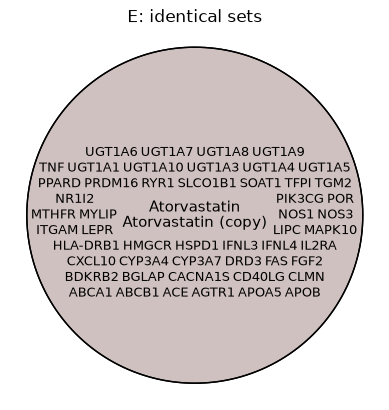

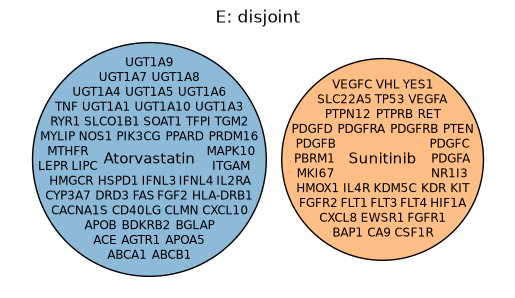

empty set: EunoiaError: invalid_combination: Invalid combination format: 'Need at least 2 non-empty sets'


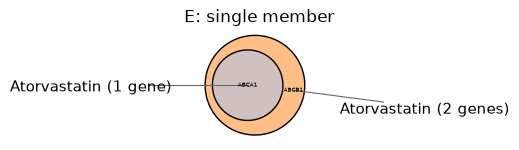

In [4]:
cases = {
    # identical sets
    "identical sets": {"Atorvastatin": A, "Atorvastatin (copy)": list(A)},
    # disjoint: shared genes removed
    "disjoint": {"Atorvastatin": [g for g in A if g not in U], "Sunitinib": [g for g in U if g not in A]},
    # empty set
    "empty set": {"Atorvastatin": A, "Sunitinib (0 genes)": []},
    # single member inside a 2-member set
    "single member": {"Atorvastatin (1 gene)": A[:1], "Atorvastatin (2 genes)": A[:2]},
}
for name, sets in cases.items():
    try:
        eu.euler(sets).plot(members={"mode": "packed"})
        plt.title(f"E: {name}")
        plt.show()
    except Exception as e:
        print(f"{name}: {type(e).__name__}: {e}")
        log("E", f"{name}: {type(e).__name__}: {e}")

## G. Contribution candidate — surface missing / false regions in the fit repr

First question: are requested-but-dropped (or drawn-but-not-requested) regions
recoverable from the fit object, or do they need Python-side reconstruction?

In [5]:
def region_check(fit, tol=1e-3):
    """Compare requested vs fitted region sizes; flag missing and false regions."""
    orig, fitted = dict(fit.original_values), dict(fit.fitted_values)
    rows = []
    for r in sorted(set(orig) | set(fitted), key=lambda k: (k.count("&"), k)):
        o, f = orig.get(r, 0.0), fitted.get(r, 0.0)
        flag = "missing" if o > 0 and f <= tol else "false" if o == 0 and f > tol else ""
        rows.append({"region": r, "requested": o, "fitted": round(f, 3), "flag": flag})
    return pd.DataFrame(rows)

region_check(fit3)

,region,requested,fitted,flag
0,Atorvastatin,35.0,35.0,
1,Simvastatin,32.0,32.0,
2,Sunitinib,35.0,35.0,
3,Atorvastatin&Simvastatin,12.0,12.0,
4,Atorvastatin&Sunitinib,2.0,2.0,
5,Atorvastatin&Simvastatin&Sunitinib,2.0,0.0,missing


In [23]:
# A config circles can't draw faithfully - does anything tell the user?
# 4 real drugs: circles drop several shared regions
hard = eu.euler({d: D[d] for d in ["Atorvastatin", "Simvastatin", "Sunitinib", "Imatinib"]})
print(hard)
region_check(hard).query("flag != ''")

EulerFit (4 circles, diag_error=0.01205, stress=0.001335, loss=0.001335)
                                                 original      fitted    residual regionError
  Atorvastatin                                         33          33   2.352e-11    0.006174
  Atorvastatin&Simvastatin                             11          11   2.845e-11    0.002058
  Atorvastatin&Simvastatin&Sunitinib                    1           0           1    0.006024
  Atorvastatin&Sunitinib                                2           2  -1.175e-10   0.0003742
  Atorvastatin&Imatinib&Simvastatin                     1           0           1    0.006024
  Atorvastatin&Imatinib&Simvastatin&Sunitinib           1           0           1    0.006024
  Atorvastatin&Imatinib                                 2           0           2     0.01205
  Simvastatin                                          31          31   5.684e-12      0.0058
  Imatinib&Simvastatin                                  1           1   2.378e-12

,region,requested,fitted,flag
4,Atorvastatin&Imatinib,2.0,0.0,missing
9,Atorvastatin&Imatinib&Simvastatin,1.0,0.0,missing
10,Atorvastatin&Simvastatin&Sunitinib,1.0,0.0,missing
11,Atorvastatin&Imatinib&Simvastatin&Sunitinib,1.0,0.0,missing


In [24]:
log("G", "TODO: are zero-count regions in original_values? decide repr extension", owner="mine-python")

## Findings summary (→ Johan)

In [25]:
pd.DataFrame(FINDINGS)

,section,owner,note
0,A,?,TODO: itemisation observations
1,B,?,TODO: glyph layout suggestions (rows/grid vs s...
2,C,johan-rust,TODO: bad label cases
3,D,?,TODO: hover / docs / missing examples
4,E,?,empty set: EunoiaError: invalid_combination: I...
5,G,mine-python,TODO: are zero-count regions in original_value...
